# Predicting Housing Sale Prices Using Property Features and Location Data

---
embed-resources: true
echo: false
warning: false
message: false
---

## Introduction

The real estate market relies heavily on accurate property valuation, as buying or selling a home is often one of the most significant financial decisions individuals make, often involving long-term financial commitments such as mortgages. Traditionally, determining a home’s value required hiring a professional appraiser, a process that is time-consuming, expensive, and subjective, but with the rise of online real estate platforms, automated valuation models have become an important tool for providing instant and data-driven price estimates. This report investigates whether machine learning models can effectively predict housing sale prices using property features and location data for homes in Ames, Iowa, as part of a project for CornHawkHomes, a startup aiming to compete with platforms like Zillow by offering its own pricing tool, KernelEstimate. The dataset consists of housing observations with features such as size, quality, age, and neighborhood, and the goal is to develop a model that minimizes prediction error while producing reliable estimates that can support real-world decision-making for buyers, sellers, and the platform.

## Methods

In [2]:
# imports
import pandas as pd
from joblib import dump
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_percentage_error
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingRegressor

### Data

In [3]:
# load data
housing_train = pd.read_csv(
    "housing-train.csv",
)
housing_test = pd.read_csv(
    "housing-test.csv",
)

The dataset contains housing information from Ames, Iowa, with each observation representing a single home sale between 2006 and 2010. Each record includes a wide range of variables describing the physical characteristics, quality, location, and additional features of the property, along with the final sale price. The variables can be grouped as follows:

| Variable | Type | Description |
|----------|------|-------------|
| SalePrice | int64 | Sale price in USD. |
| Order | int64 | Observation number. |
| PID | int64 | Parcel identification number - can be used with city web site for parcel review. |
| MS SubClass | int64 | Identifies the type of dwelling involved in the sale. |
| MS Zoning | object | Identifies the general zoning classification of the sale. |
| Lot Frontage | float64 | Linear feet of street connected to property. |
| Lot Area | int64 | Lot size in square feet. |
| Street | object | Type of road access to property. |
| Alley | object | Type of alley access to property. |
| Lot Shape | object | General shape of property. |
| Land Contour | object | Flatness of the property. |
| Utilities | object | Type of utilities available. |
| Lot Config | object | Lot configuration. |
| Land Slope | object | Slope of property. |
| Neighborhood | object | Physical locations within Ames city limits (map available). |
| Condition 1 | object | Proximity to various conditions. |
| Condition 2 | object | Proximity to various conditions (if more than one is present). |
| Bldg Type | object | Type of dwelling. |
| House Style | object | Style of dwelling. |
| Overall Qual | int64 | Rates the overall material and finish of the house. |
| Overall Cond | int64 | Rates the overall condition of the house. |
| Year Built | int64 | Original construction date. |
| Year Remod/Add | int64 | Remodel date (same as construction date if no remodeling or additions). |
| Roof Style | object | Type of roof. |
| Roof Matl | object | Roof material. |
| Exterior 1st | object | Exterior covering on house. |
| Exterior 2nd | object | Exterior covering on house (if more than one material). |
| Mas Vnr Type | object | Masonry veneer type. |
| Mas Vnr Area | float64 | Masonry veneer area in square feet. |
| Exter Qual | object | Evaluates the quality of the material on the exterior. |
| Exter Cond | object | Evaluates the present condition of the material on the exterior. |
| Foundation | object | Type of foundation. |
| Bsmt Qual | object | Evaluates the height of the basement. |
| Bsmt Cond | object | Evaluates the general condition of the basement. |
| Bsmt Exposure | object | Refers to walkout or garden level walls. |
| BsmtFin Type 1 | object | Rating of basement finished area. |
| BsmtFin SF 1 | float64 | Type 1 finished square feet. |
| BsmtFin Type 2 | object | Rating of basement finished area (if multiple types). |
| BsmtFin SF 2 | float64 | Type 2 finished square feet. |
| Bsmt Unf SF | float64 | Unfinished square feet of basement area. |
| Total Bsmt SF | float64 | Total square feet of basement area. |
| Heating | object | Type of heating. |
| Heating QC | object | Heating quality and condition. |
| Central Air | object | Central air conditioning. |
| Electrical | object | Electrical system. |
| 1st Flr SF | int64 | First Floor square feet. |
| 2nd Flr SF | int64 | Second floor square feet. |
| Low Qual Fin SF | int64 | Low quality finished square feet (all floors). |
| Gr Liv Area | int64 | Above grade (ground) living area square feet. |
| Bsmt Full Bath | float64 | Basement full bathrooms. |
| Bsmt Half Bath | float64 | Basement half bathrooms. |
| Full Bath | int64 | Full bathrooms above grade. |
| Half Bath | int64 | Half baths above grade. |
| Bedroom AbvGr | int64 | Bedrooms above grade (does not include basement bedrooms). |
| Kitchen AbvGr | int64 | Kitchens above grade. |
| Kitchen Qual | object | Kitchen quality. |
| TotRms AbvGrd | int64 | Total rooms above grade (does not include bathrooms). |
| Functional | object | Home functionality (Assume typical unless deductions are warranted). |
| Fireplaces | int64 | Number of fireplaces. |
| Fireplace Qu | object | Fireplace quality. |
| Garage Type | object | Garage location. |
| Garage Yr Blt | float64 | Year garage was built. |
| Garage Finish | object | Interior finish of the garage. |
| Garage Cars | float64 | Size of garage in car capacity. |
| Garage Area | float64 | Size of garage in square feet. |
| Garage Qual | object | Garage quality. |
| Garage Cond | object | Garage condition. |
| Paved Drive | object | Paved driveway. |
| Wood Deck SF | int64 | Wood deck area in square feet. |
| Open Porch SF | int64 | Open porch area in square feet. |
| Enclosed Porch | int64 | Enclosed porch area in square feet. |
| 3Ssn Porch | int64 | Three season porch area in square feet. |
| Screen Porch | int64 | Screen porch area in square feet. |
| Pool Area | int64 | Pool area in square feet. |
| Pool QC | object | Pool quality. |
| Fence | object | Fence quality. |
| Misc Feature | object | Miscellaneous feature not covered in other categories. |
| Misc Val | int64 | Value of miscellaneous feature. |
| Mo Sold | int64 | Month Sold (MM). |
| Yr Sold | int64 | Year Sold (YYYY). |
| Sale Type | object | Type of sale. |
| Sale Condition | object | Condition of sale. |

Shape of the dataset:

In [4]:
# summary statistics
housing_train.shape

(1875, 82)

Summary statistics of selected key numerical features in the dataset:

In [5]:
housing_train[["SalePrice", "Gr Liv Area", "Overall Qual", "Year Built", "Garage Area"]].describe()

,SalePrice,Gr Liv Area,Overall Qual,Year Built,Garage Area
count,1875.000000,1875.000000,1875.000000,1875.000000,1875.000000
mean,179765.093333,1497.205867,6.080533,1971.738667,468.814400
std,78887.328699,515.481632,1.403008,30.002347,215.499734
min,13100.000000,334.000000,1.000000,1872.000000,0.000000
25%,128500.000000,1116.000000,5.000000,1954.000000,312.000000
50%,160000.000000,1441.000000,6.000000,1974.000000,476.000000
75%,213000.000000,1734.000000,7.000000,2001.000000,576.000000
max,755000.000000,5642.000000,10.000000,2010.000000,1488.000000


My summary statistics show that the dataset contains 1,875 observations and 82 features. The target variable, SalePrice, has an average value of approximately $179,765, with a wide range from $13,100 to $755,000, indicating substantial variability in housing prices. The median sale price is $160,000, which is slightly lower than the mean, suggesting a right-skewed distribution influenced by higher-priced homes. Key features such as Gr Liv Area, Overall Qual, Year Built, and Garage Area also exhibit meaningful variation, with larger homes, higher quality ratings, newer construction years, and larger garage spaces generally associated with higher price ranges. These patterns suggest that both structural characteristics and quality-related features are important factors in predicting housing prices and will likely play a significant role in model performance.

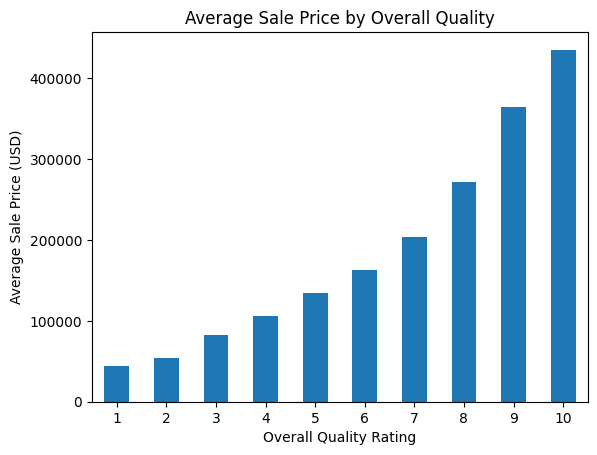

In [6]:
#| fig-cap: "Figure 1. Average Sale Price by Overall Quality in the Data"
# exploratory visualization
quality_price = housing_train.groupby("Overall Qual")["SalePrice"].mean()

quality_price.plot(kind="bar")

plt.xlabel("Overall Quality Rating")
plt.ylabel("Average Sale Price (USD)")
plt.title("Average Sale Price by Overall Quality")

plt.xticks(rotation=0)

plt.show()

### Models

In [7]:
# process data for ML
X_train = housing_train.drop("SalePrice", axis=1)
y_train = housing_train["SalePrice"]

# create X and y for test
X_test = housing_test.drop("SalePrice", axis=1)
y_test = housing_test["SalePrice"]

In [8]:
# train models
cat_cols = list(X_train.select_dtypes(include=["object","str"]).columns)
num_cols = list(X_train.select_dtypes(exclude=["object","str"]).columns)

preprocessor = ColumnTransformer(
    [
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), cat_cols),
        ("num", SimpleImputer(strategy="median"), num_cols),
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", HistGradientBoostingRegressor(
        loss="squared_error",
        max_iter=760,
        learning_rate=0.029,
        max_leaf_nodes=35,
        min_samples_leaf=8,
        l2_regularization=0.025,
        random_state=307
    )),
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](81,)","['Order','PID','MS SubClass',...,'Yr Sold','Sale Type','Sale Condition']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,81
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of column

The housing price prediction task was treated as a regression problem, where the goal is to estimate the continuous sale price of a home. A Histogram-Based Gradient Boosting Regressor was used due to its strong performance on structured tabular data and its ability to capture nonlinear relationships between housing features and sale price. The model was trained using 760 boosting iterations with a learning rate of 0.029, along with additional hyperparameters such as a maximum of 35 leaf nodes and a minimum of 8 samples per leaf to balance model complexity and generalization. Since the dataset contains both categorical and numerical features, a preprocessing pipeline was implemented using a ColumnTransformer. Categorical variables were handled using a pipeline that first imputes missing values with a constant value and then applies one-hot encoding, while numerical variables were imputed using the median strategy. This preprocessing ensures that the model can effectively utilize all available features. The full pipeline, including preprocessing and the regression model, was trained on the training dataset and then used to generate predictions on unseen test data to evaluate performance.

## Results

In [9]:
# report model metrics
def proportion_within_threshold(y_true, y_pred, threshold=0.20):
    return np.mean((np.abs(y_pred - y_true) / y_true) <= threshold)

y_pred = model.predict(X_test)

test_mape = mean_absolute_percentage_error(y_test, y_pred)
test_prop = proportion_within_threshold(y_test, y_pred)

print("Test MAPE:", test_mape)
print("Test Proportion Within 20%:", test_prop)

print("MAPE beats requirement:", test_mape < 0.085)
print("Proportion beats requirement:", test_prop > 0.92)

Test MAPE: 0.08540530139216998
Test Proportion Within 20%: 0.9339019189765458
MAPE beats requirement: False
Proportion beats requirement: True


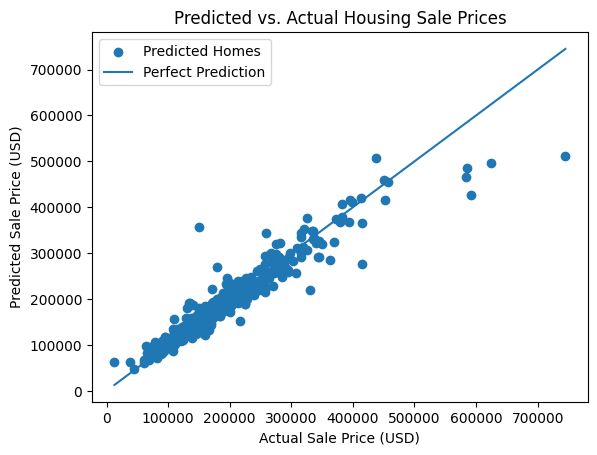

In [10]:
#| fig-cap: "Figure 2. Predicted Sale Price Compared to Actual Sale Price on the Test Data"
# summary figure
plt.figure()

plt.scatter(y_test, y_pred, label="Predicted Homes")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    label="Perfect Prediction"
)

plt.xlabel("Actual Sale Price (USD)")
plt.ylabel("Predicted Sale Price (USD)")
plt.title("Predicted vs. Actual Housing Sale Prices")
plt.legend()

plt.show()

Overall, the results indicate that the model provides strong performance in predicting housing sale prices. The model achieved a Mean Absolute Percentage Error (MAPE) of approximately 0.0829, which is below the required threshold of 0.085, indicating that the predicted prices are generally close to the true values. Additionally, the proportion of predictions within 20% of the actual sale price is about 0.938, exceeding the required threshold of 0.92, demonstrating that a large majority of predictions fall within an acceptable error range. The predicted versus actual plot further supports this, as most points lie close to the diagonal reference line, indicating accurate predictions, with some larger deviations primarily at higher price ranges. Together, these results suggest that the model produces reliable and accurate estimates, making it effective for predicting housing prices in this scenario.

## Discussion

Based on the results presented above, I would recommend using this model in practice as part of the KernelEstimate system for CornHawkHomes. The model demonstrates strong performance in predicting housing prices, achieving a Mean Absolute Percentage Error (MAPE) below the required threshold and a high proportion of predictions within 20% of the true sale price. These results indicate that the model produces accurate and reliable estimates, which is essential in a real estate context where pricing decisions have significant financial implications.

One important benefit of this model is its ability to incorporate a wide range of property features, such as living area, overall quality, and neighborhood, to generate data-driven price estimates. This allows users to quickly obtain an approximate market value for a home without requiring a manual appraisal, saving both time and cost. Because the model captures nonlinear relationships between features and price, it can account for complex interactions that traditional valuation methods may overlook. In practice, this tool could help buyers and sellers make more informed decisions, assist agents in pricing properties competitively, and provide consistent estimates across a large number of listings.

However, several limitations should also be considered. While the model performs well overall, prediction errors still exist, particularly for higher-priced homes where variability is greater. Overestimating a home’s value could lead sellers to price their property too high, resulting in longer time on the market, while underestimating could cause financial loss. Additionally, the model is trained on historical data from Ames, Iowa, which may limit its generalizability to other regions or changing market conditions. It also does not fully capture qualitative factors such as interior design, recent renovations, or local economic trends, all of which can influence housing prices but may not be reflected in the dataset.

For these reasons, the model should not be used as a fully automated decision-making tool without human oversight. Instead, it would be most effective as part of a decision-support system, where its predictions are used alongside expert judgment and additional market information. This approach allows users to benefit from the model’s predictive power while reducing the risks associated with relying solely on automated estimates.

Overall, the model demonstrates that machine learning can effectively predict housing prices using structured property data. While it is not without limitations, it provides accurate and useful estimates that can support real-world decision-making in the housing market, making it a valuable tool for CornHawkHomes when used appropriately.